# Ducks in Virginia: observations, migration seasons, and water

**Where are ducks reported in Virginia, how do their modeled seasons differ,
and which mapped water features sit near those records?**

Two TypeScript VGI workers share one DuckDB session:
[vgi-ducks](https://github.com/Query-farm/vgi-ducks) supplies duck taxonomy and
**eBird Status and Trends** seasonal ranges and weekly abundance;
[vgi-overture-maps-typescript](https://github.com/Query-farm/vgi-overture-maps-typescript)
supplies Virginia's boundary and local water polygons.
Public **iNaturalist Research-grade Observations via GBIF, dated 2024–2025**
add actual observation locations.

The notebook distinguishes observation-record counts from the **2023 eBird model**.
Neither represents a current population census or a live migration forecast.


**Reader edition:** setup and plotting code are omitted so GitHub displays the analysis and figures. To rerun, open the [complete executable notebook](virginia-ducks.source.ipynb). Viewing needs no key; regenerating requires your own `EBIRDST_KEY`.

## 1. Use Virginia's boundary, not just a rectangular search

A record labeled “Virginia” can lie across a state line or in neighboring waters.
We retrieve both the land and territorial versions of Virginia from Overture,
then keep duck coordinates covered by its **territorial** boundary. The land
polygon gives the maps a coastline.

The four bounding-box predicates below constrain the Overture scan. Its catalog
enforces them before DuckDB reads the GeoParquet data.


In [4]:
%%sql
CREATE TEMP TABLE virginia AS
SELECT id, names.primary AS name, is_land, is_territorial, geometry
FROM overture.divisions.division_area
WHERE bbox.xmin BETWEEN -84 AND -75 AND bbox.xmax BETWEEN -84 AND -75
  AND bbox.ymin BETWEEN 36 AND 40 AND bbox.ymax BETWEEN 36 AND 40
  AND subtype = 'region' AND country = 'US' AND region = 'US-VA';

SELECT name, is_land, is_territorial,
       round(ST_Area_Spheroid(geometry) / 1000000) AS area_km2
FROM virginia ORDER BY is_territorial DESC;


,name,is_land,is_territorial,area_km2
0,Virginia,False,True,110757.0
1,Virginia,True,False,104738.0


The input is restricted to one source dataset, human observations marked present,
2024–2025 dates, known coordinate uncertainty of **250 m or less**, no GBIF-flagged
geospatial issue, and record licenses CC0 or CC BY. These filters create a selected
public-record dataset; they do not establish complete coverage of Virginia.

The SQL join below uses the worker's extant duck catalog to exclude geese, swans,
and names that do not match. GBIF's accepted species names are matched exactly;
there is no guessed mapping between taxonomies. A second spatial filter removes
coordinates outside the state.


In [5]:
%%sql
CREATE TEMP TABLE input_records AS
SELECT * FROM read_json(getvariable('observations_file'));

CREATE TEMP TABLE matched_ducks AS
SELECT r.*, s.common_name, s.species_code,
       ST_Point(r.longitude, r.latitude) AS point
FROM input_records AS r
JOIN ducks.main.species AS s
  ON r.scientific_name = s.scientific_name AND NOT s.extinct
WHERE try_cast(r.observation_date AS DATE) IS NOT NULL;

CREATE TEMP TABLE virginia_ducks AS
SELECT r.* FROM matched_ducks AS r
WHERE EXISTS (
  SELECT 1 FROM virginia AS v
  WHERE v.is_territorial AND ST_Covers(v.geometry, r.point)
);

SELECT (SELECT count(*) FROM input_records) AS eligible_waterfowl_records,
       (SELECT count(*) FROM matched_ducks) AS duck_catalog_matches,
       count(*) AS duck_records_inside_virginia,
       count(DISTINCT species_code) AS duck_species
FROM virginia_ducks;


,eligible_waterfowl_records,duck_catalog_matches,duck_records_inside_virginia,duck_species
0,800,582,580,29


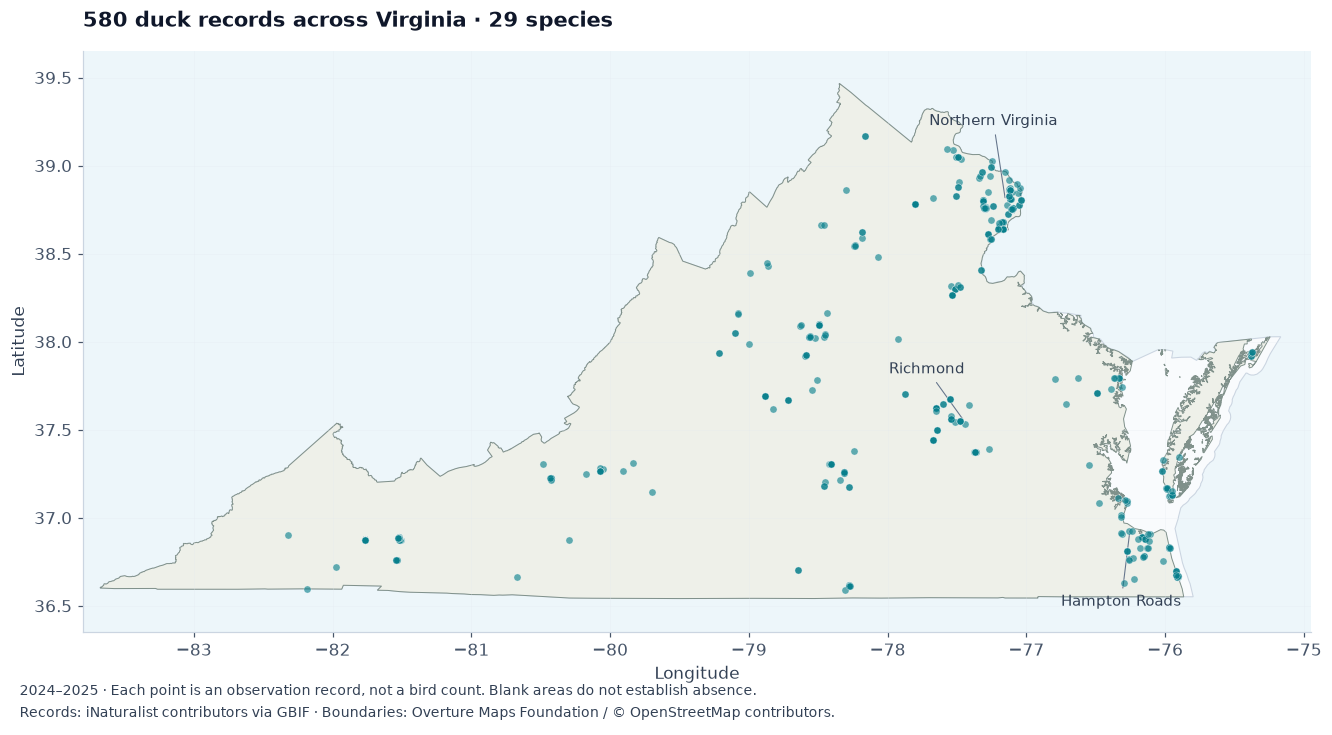

## 2. Which ducks appear in these records?

The ranking describes **retained observation records in this source**, not which
species is most abundant in Virginia. Birders' locations, identification habits,
photographs, and licensing choices all influence the records available here.


In [9]:
%%sql species_counts <<
SELECT common_name, scientific_name, species_code, count(*) AS records,
       count(DISTINCT observation_month) AS months_with_records
FROM virginia_ducks
GROUP BY ALL
ORDER BY records DESC, common_name;


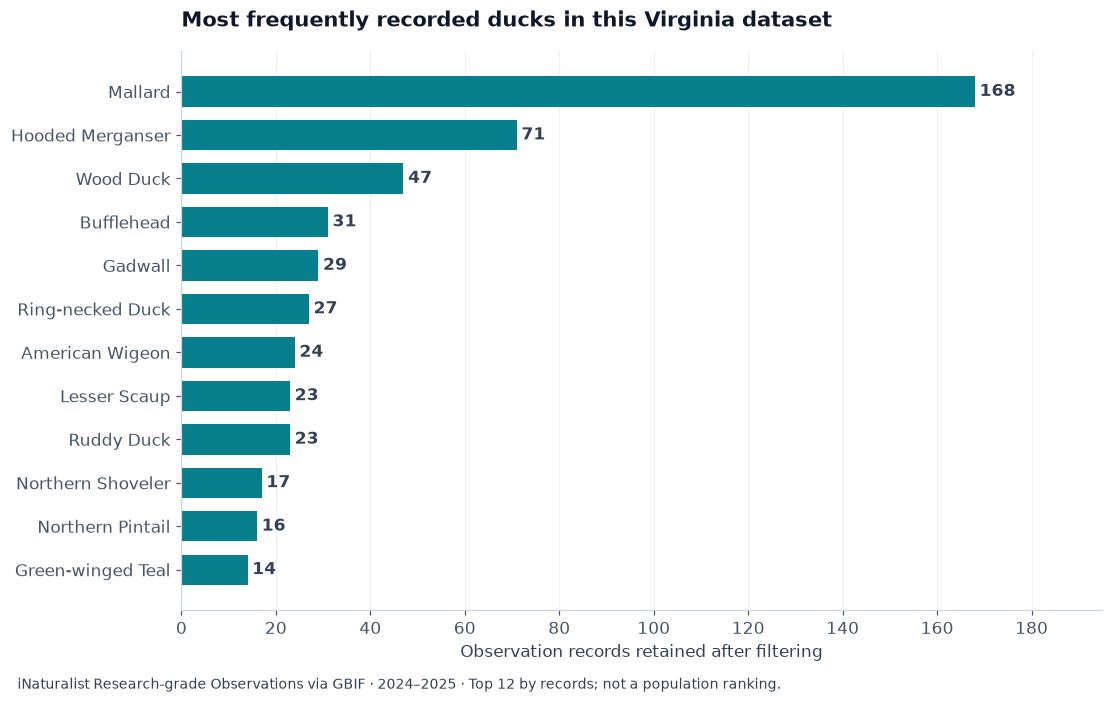

## 3. How do the reported seasons differ?

We count records by species and calendar month across two complete years.
The heatmap compares each species with its own annual total: **color is the
percentage of that species' records in the month; cell numbers are record counts**.
A zero means no retained record in this dataset, not that the duck was absent.

These are descriptive reporting patterns. They do not control for observer
effort and must not be read as migration probabilities or arrival dates.


In [11]:
%%sql monthly <<
SELECT common_name, observation_month AS month, count(*) AS records
FROM virginia_ducks
GROUP BY common_name, observation_month
ORDER BY common_name, month;


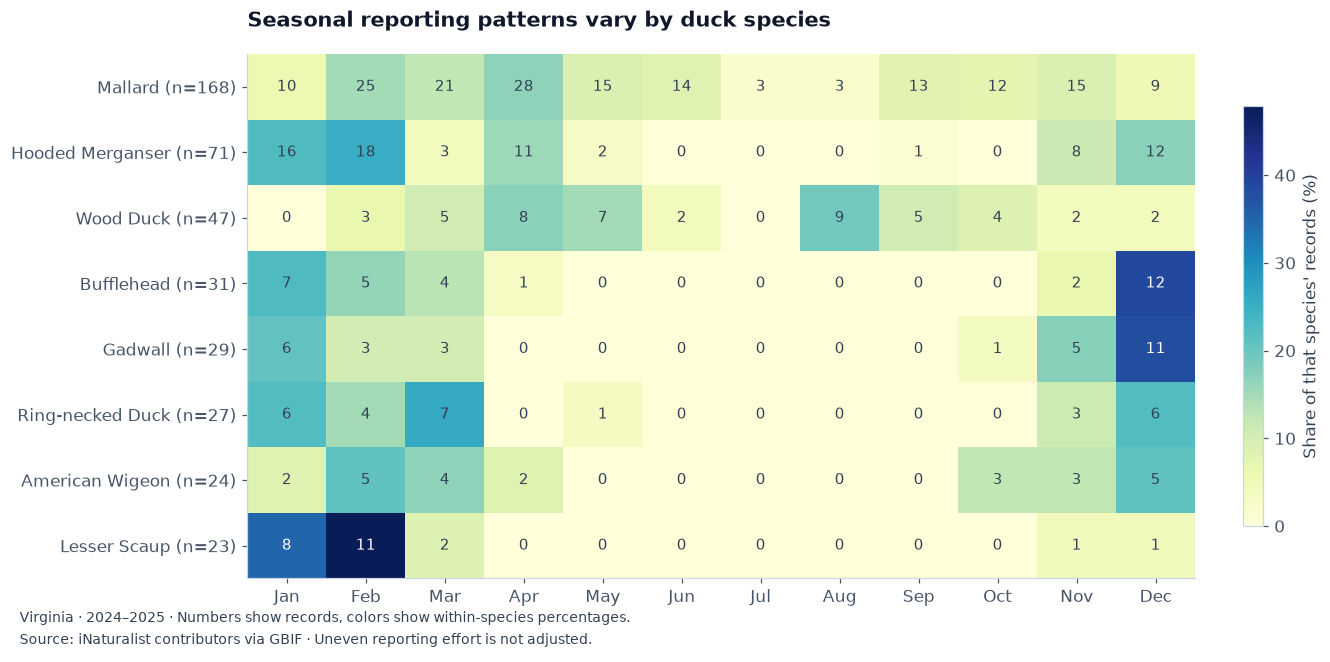

## 4. Measure the modeled annual cycle inside Virginia

The observation heatmap measures reporting. The next chart uses Cornell's
**effort-standardized relative-abundance model**, queried through `vgi-ducks`.
Wood Duck, Bufflehead, and Blue-winged Teal show contrasting annual cycles.
All three selected 2023 products have a seasonal review quality of 3 in Cornell's
product configuration; this does not remove model uncertainty.

We simplify Overture's territorial boundary to a tolerance of 0.01 degrees
(roughly 1 km) before passing it as WKT to the worker. The worker selects native
**27 km Equal Earth grid cells whose centers fall inside that polygon**.
This is an equal-weight mean over modeled cells, not an exact area-weighted clip.
It is a statewide summary; small bays and individual ponds are below its resolution.

Relative abundance is the expected bird count on a standardized one-hour,
two-kilometer checklist under the model's observation conditions. The panels use
separate vertical scales. Missing cells are excluded, genuine zero remains zero,
and the lower panel reports modeled-cell coverage. These curves describe the
**2023 model year**, not the 2024–2025 observation snapshot above.


In [13]:
%%sql
CREATE TEMP TABLE model_region AS
SELECT ST_SimplifyPreserveTopology(geometry,0.01) AS geometry
FROM virginia WHERE is_territorial;
SET VARIABLE virginia_wkt = (SELECT ST_AsText(geometry) FROM model_region);
SELECT ST_NPoints(geometry) AS vertices, ST_IsValid(geometry) AS valid,
       round(ST_Area(ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true))/1e6) AS area_km2
FROM model_region;


,vertices,valid,area_km2
0,181,True,110279.0


In [14]:
%%sql
CREATE TEMP TABLE weekly_models AS
SELECT 'Wood Duck' AS common_name, * FROM ducks.main.weekly_abundance(
  'wooduc', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km')
UNION ALL
SELECT 'Bufflehead' AS common_name, * FROM ducks.main.weekly_abundance(
  'buffle', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km')
UNION ALL
SELECT 'Blue-winged Teal' AS common_name, * FROM ducks.main.weekly_abundance(
  'buwtea', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km');

SELECT common_name, count(*) AS weeks,
       min(selected_cell_count) AS selected_cells,
       round(min(coverage_fraction),3) AS minimum_coverage,
       round(max(coverage_fraction),3) AS maximum_coverage
FROM weekly_models GROUP BY common_name ORDER BY common_name;


,common_name,weeks,selected_cells,minimum_coverage,maximum_coverage
0,Blue-winged Teal,52,149,1.0,1.0
1,Bufflehead,52,149,1.0,1.0
2,Wood Duck,52,149,1.0,1.0


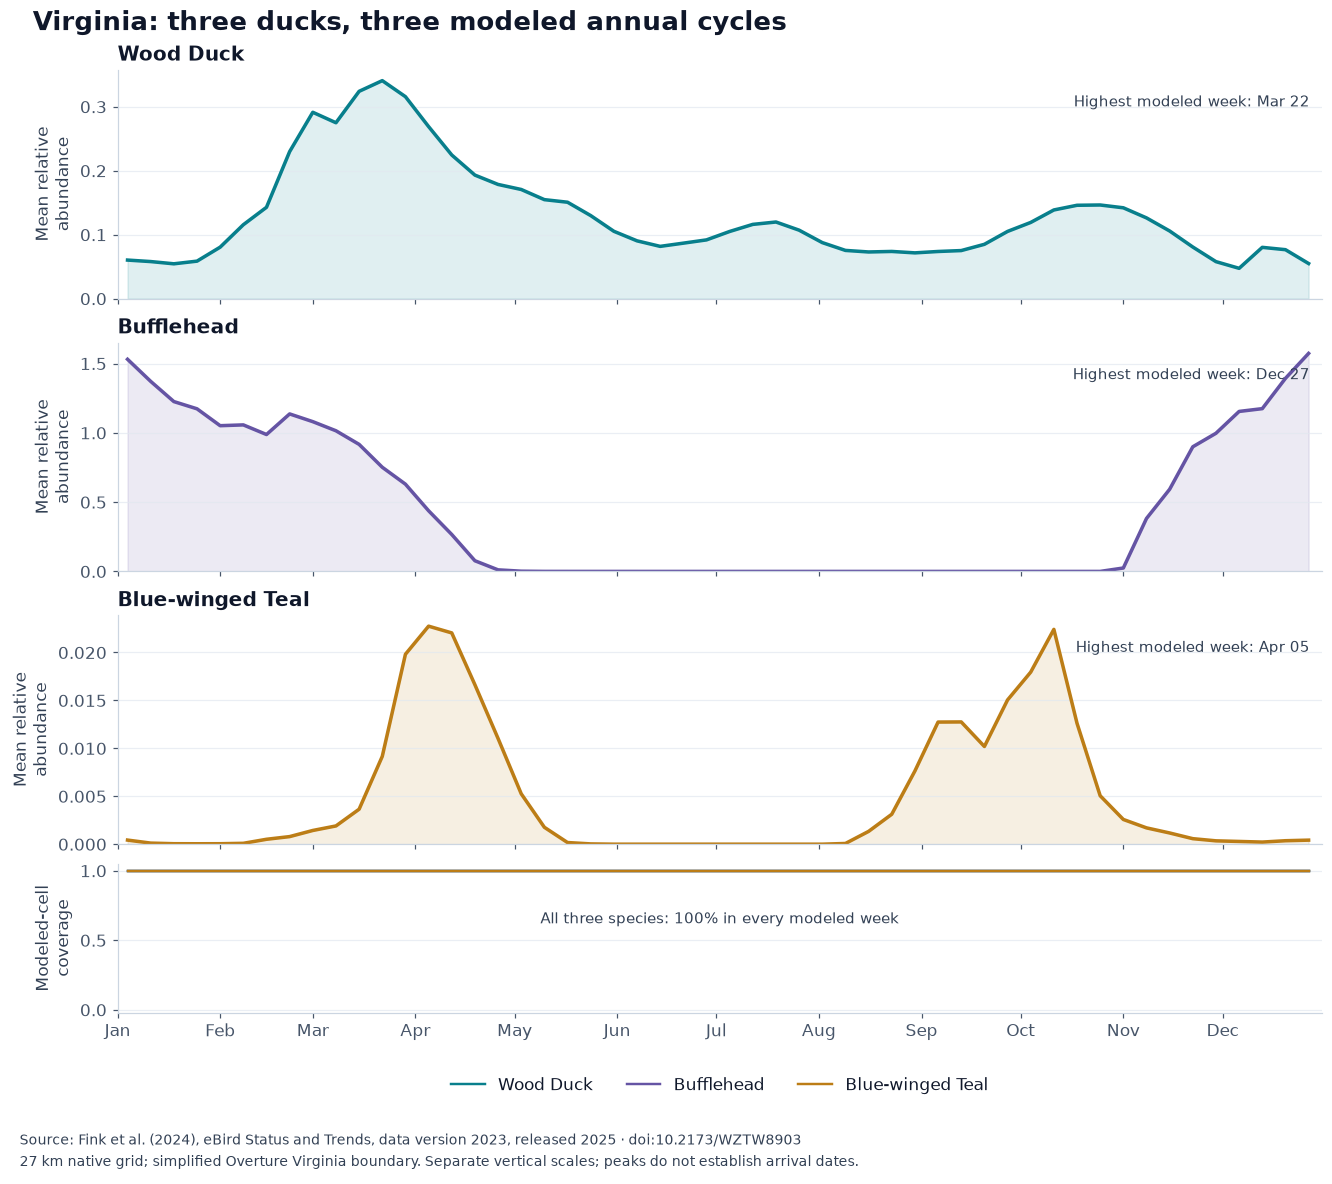

### Join seasonal range polygons to the state

A second spatial integration intersects each seasonal range with Overture's
Virginia boundary. The table measures the **percentage of Virginia's territory
intersected by each smoothed range**, not the percentage of birds or suitable
habitat. The 27 km range polygons are intentionally coarse.
Season dates describe Cornell's species-wide model seasons; they are not
Virginia-specific arrival and departure dates. Winter dates can wrap New Year.


In [17]:
%%sql
CREATE TEMP TABLE seasonal_models AS
SELECT * FROM ducks.main.seasonal_ranges('wooduc',data_year:=2023,resolution:='27km')
UNION ALL
SELECT * FROM ducks.main.seasonal_ranges('buffle',data_year:=2023,resolution:='27km')
UNION ALL
SELECT * FROM ducks.main.seasonal_ranges('buwtea',data_year:=2023,resolution:='27km');

SELECT r.common_name, r.season, r.start_date, r.end_date, r.wraps_year,
       round(100 * ST_Area(ST_Transform(
         ST_Intersection(ST_GeomFromWKB(r.geometry_wkb),v.geometry),
         'OGC:CRS84','EPSG:26918',always_xy:=true)) /
         ST_Area(ST_Transform(v.geometry,'OGC:CRS84','EPSG:26918',always_xy:=true)),1)
         AS virginia_territory_percent
FROM seasonal_models r CROSS JOIN virginia v
WHERE v.is_territorial
ORDER BY r.common_name,r.season;


,common_name,season,start_date,end_date,wraps_year,virginia_territory_percent
0,Blue-winged Teal,breeding,2023-06-14,2023-07-12,False,0.0
1,Blue-winged Teal,nonbreeding,2023-12-27,2023-01-25,True,1.2
2,Blue-winged Teal,postbreeding_migration,2023-07-19,2023-12-20,False,64.4
3,Blue-winged Teal,prebreeding_migration,2023-02-01,2023-06-07,False,75.7
4,Bufflehead,breeding,2023-06-07,2023-07-19,False,0.8
5,Bufflehead,nonbreeding,2023-12-27,2023-02-15,True,64.0
6,Bufflehead,postbreeding_migration,2023-07-26,2023-12-20,False,87.8
7,Bufflehead,prebreeding_migration,2023-02-22,2023-05-31,False,77.3
8,Wood Duck,breeding,2023-04-26,2023-06-21,False,96.4
9,Wood Duck,nonbreeding,2023-12-06,2023-01-25,True,86.0


## 5. Put the duck records beside mapped water

Overture adds context that the bird records do not contain. We inspect three
bounded windows: **Northern Virginia, Richmond, and Hampton Roads**. The query
below retains overlapping water polygons, including coastal water, and excludes
swimming pools, drains, and wastewater features.

These are mapped water features, **not a habitat-suitability or public-access map**.
Some wetlands and seasonal water are missing. Water boundaries come from the
2026 Overture release, while the observations are from 2024–2025.


In [19]:
%%sql
CREATE TEMP TABLE local_water AS
SELECT 'Northern Virginia' AS focus, id, names.primary AS name, subtype, class, geometry
FROM overture.base.water
WHERE bbox.xmin <= -76.95 AND bbox.xmax >= -77.4
  AND bbox.ymin <= 39.05 AND bbox.ymax >= 38.55
  AND ST_GeometryType(geometry) IN ('POLYGON','MULTIPOLYGON')
  AND (subtype IN ('lake','pond','river','stream','ocean')
       OR (subtype='water' AND class='water')
       OR (subtype='reservoir' AND class='reservoir'));


,Success


### Ask a spatial question, with distances in meters

For each window, we test whether each record lies within **500 m** of at least
one selected water polygon. We project the geometries into UTM zone 18N for this
local distance calculation. `EXISTS` keeps one row per observation even when
several water features overlap.

Coordinate uncertainty is up to 250 m, so this is an approximate contextual
comparison. A record near water does not prove habitat use; a record outside the
buffer does not prove the absence of water.


In [21]:
%%sql
CREATE TEMP TABLE water_m AS
SELECT *, ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true) AS geom_m
FROM local_water;

CREATE TEMP TABLE focus_records AS
SELECT f.name AS focus, r.*,
       ST_Transform(r.point,'OGC:CRS84','EPSG:26918',always_xy:=true) AS point_m
FROM virginia_ducks AS r JOIN focus_regions AS f
  ON r.longitude BETWEEN f.west AND f.east
 AND r.latitude BETWEEN f.south AND f.north;

CREATE TEMP TABLE water_context AS
SELECT r.*, EXISTS (
  SELECT 1 FROM water_m AS w
  WHERE w.focus=r.focus AND ST_DWithin(w.geom_m,r.point_m,500)
) AS within_500m_of_mapped_water
FROM focus_records AS r;

SELECT focus, count(*) AS records, count(DISTINCT species_code) AS duck_species,
       count(*) FILTER (WHERE within_500m_of_mapped_water) AS records_near_water
FROM water_context GROUP BY focus ORDER BY focus;


,focus,records,duck_species,records_near_water
0,Hampton Roads,64,15,62
1,Northern Virginia,206,19,183
2,Richmond,29,13,28


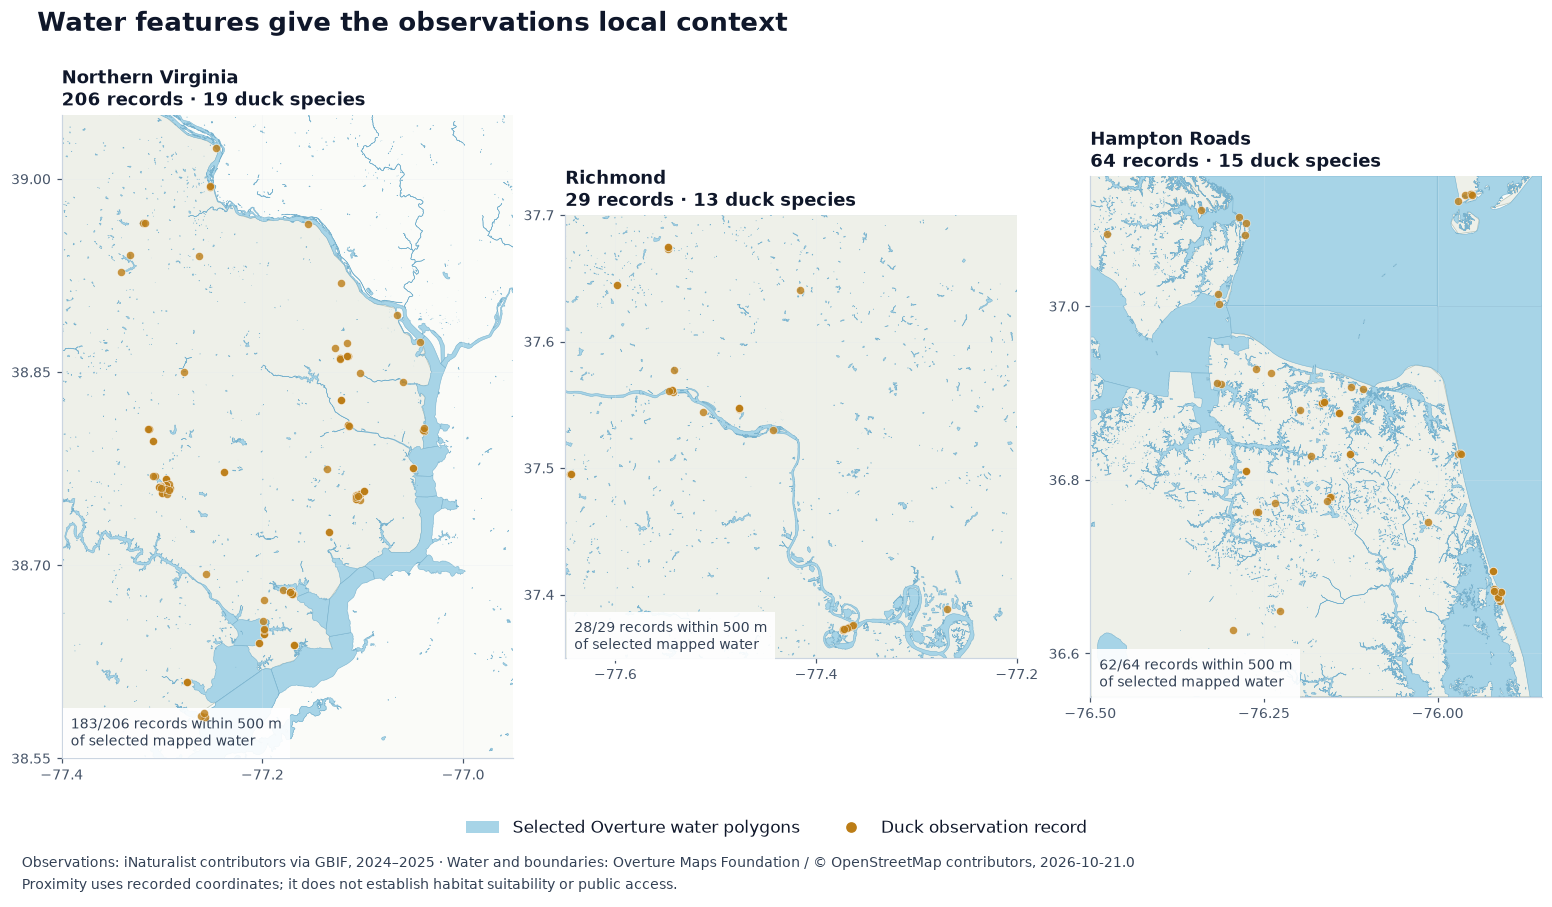

### Connect records to named water features

This final join lists named features with nearby records in the three windows.
A record can appear near more than one named feature, so these counts must not be
summed to obtain a total. They describe spatial proximity, not visitor access or
confirmed use of a particular water body.


In [25]:
%%sql
SELECT w.focus, w.name AS water_feature,
       count(DISTINCT r.gbif_id) AS nearby_records,
       count(DISTINCT r.species_code) AS duck_species
FROM water_m AS w JOIN focus_records AS r
  ON w.focus=r.focus AND ST_DWithin(w.geom_m,r.point_m,500)
WHERE w.name IS NOT NULL
GROUP BY w.focus,w.name
ORDER BY nearby_records DESC,w.focus,water_feature
LIMIT 10;


,focus,water_feature,nearby_records,duck_species
0,Northern Virginia,Burke Lake,38,14
1,Northern Virginia,Pohick Bay,18,10
2,Hampton Roads,Lake Smith,8,5
3,Northern Virginia,Belmont Bay,8,5
4,Northern Virginia,Cameron Run,6,3
5,Northern Virginia,Sparrow Pond,5,1
6,Hampton Roads,Lake Lawson,4,3
7,Hampton Roads,Lake Rudee,4,3
8,Hampton Roads,Lake Wesley,4,3
9,Hampton Roads,Rudee Inlet,4,3


## What this notebook establishes

It shows actual public duck observations in Virginia and demonstrates how the two
VGI workers can join species data to geographic features. It does not estimate
population size, identify arrival dates, or recommend access to private land.
The eBird model adds effort-standardized annual cycles and range polygons.
A local peak can reflect breeding or winter residence, not a migration event.
Coverage is the share of selected grid centers with modeled values; it is not
an uncertainty interval or the fraction of Virginia's area modeled.

**Sources and scope**

- Fink et al. (2024), [eBird Status and Trends, data version 2023, released 2025](https://doi.org/10.2173/WZTW8903), Cornell Lab of Ornithology. [Product methods and interpretation](https://ebird.github.io/ebirdst/articles/status.html). These derived charts use authenticated products; no key or source raster is included in the repository. [Status and Trends](https://science.ebird.org/en/status-and-trends) data retain Cornell's terms.

- [iNaturalist Research-grade Observations via GBIF](https://doi.org/10.15468/ab3s5x), contributed by iNaturalist observers. The query retains only records with CC0 or CC BY licenses; licenses and original record links remain in the local data cache. No observation photos are copied.
- [GBIF occurrence API](https://techdocs.gbif.org/en/openapi/v1/occurrence): all pages of the bounded 2024–2025 Virginia query are retrieved. This is a selected source, not an exhaustive bird inventory.
- [Overture divisions](https://docs.overturemaps.org/guides/divisions/) and [water](https://docs.overturemaps.org/schema/reference/base/water/), release **2026-10-21.0**. Water features derive from OpenStreetMap contributors. Source data retain their upstream licenses; see [Overture attribution](https://docs.overturemaps.org/attribution/).
- [Duck taxonomy scope](../data/README.md): extant exact scientific-name matches to the worker's eBird 2026 duck catalog. Unmatched names, geese, and swans are excluded.

The local cache records the exact API filters, retrieval time, and SHA256. Refreshes
can change counts as GBIF receives new records or corrections. The saved charts
are a snapshot of the recorded execution. The executable notebook preserves the
setup; the reader edition omits it for GitHub.


**Execution snapshot:** 2026-11-13T12:50:52.369841-05:00. GBIF retrieved 2026-11-13T17:38:53.363180+00:00: 800 eligible Anatidae records, 580 duck records inside Virginia, 29 species. Overture release `2026-10-21.0`, worker commit `d23d65e422d2b93a7faa264c718691520a05bd23`. eBird model: 2023, 27 km, 52 weeks each for three species. Duck worker: `v0.1.0`; DuckDB: `2.0.0`.

Observation-cache SHA256: `8ceba202b0ff6313768f19120c96ccc47391bd124bbd0958b05bfd63c9203238`.